# English label proportions: ours against WebOrganizer's

**Question:** are the topic and format proportions of our English HPLT data, labelled by
Qwen3.8-27B, similar to the proportions the original WebOrganizer work reports for its
English corpus? If not, is the difference in the labeller or in the web pages?

**Data:**

- **WebOrganizer's published proportions:** 24 topic and 24 format shares in whole percent
  (FAQ 0.4%), hard-coded in the *Parameters* cell as provided on 25 November 2026. Rounding
  makes them sum to 101–101.4%, so they are renormalised to 100.
- **Llama on WebOrganizer's pages:** `results/datasets/{topic,format}/weborganizer-405B`,
  the 10,000 validation pages of WebOrganizer's annotation data with Llama-3.1-405B's
  label distributions (the labeller WebOrganizer distilled from).
- **Qwen on the same pages:** `results/distribution/Qwen3.8-27B-weborganizer-annotations/{topic,format}/validation.jsonl`,
  our prompt and labeller on those 10,000 pages.
- **Qwen on our English pages:** `results/distribution/Qwen3.8-27B-hplt-annotations/<collection>/{topic,format}/english.jsonl`,
  for the three HPLT 4.0 collections clean, noisy and poor. Each file is read up to the
  number of documents the training dataset used (25,000, 25,000 and 10,000), the same
  documents as `results/datasets/<type>/hplt-finetune`; the notebook checks its sums
  against that dataset's `label_counts.tsv`.

**Method:**

- Our labels have 26 classes; Other and Bad example are dropped and the remaining 24 shares
  renormalised, as in every comparison with WebOrganizer.
- A label's share is its mean probability over the pages (**per document**), or its
  probability weighted by the page's length in characters (**per character**, a stand-in for
  tokens).
- Distances are Jensen-Shannon divergences (JSD) in bits: 0 for identical distributions, 1
  for distributions with no label in common. For scale, the notebook also gives the distance
  between English and German, and English and Finnish, in our clean data.

Run time is about 2–3 minutes over sshfs, nearly all of it reading the HPLT English files
(about 0.9 GB). The notebook writes nothing.

## Setup

Imports, the repository root, the chart style and the helpers.

- **Colours:** WebOrganizer's published shares are a black ring. Llama on WebOrganizer's
  pages is orange, Qwen on WebOrganizer's pages aqua, and Qwen on our HPLT pages blue (the
  first three slots of a colour-blind-checked palette, as in `weborganizer_comparison.ipynb`:
  blue ours, orange WebOrganizer's). Differences use a blue–grey–red scale.
- **`js_bits`** is the Jensen-Shannon divergence in bits; **`to_percent`** renormalises
  a vector of label weights to percentages over the 24 shared labels.

In [1]:
from __future__ import annotations

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_from_disk
from IPython.display import Markdown, display
from matplotlib.lines import Line2D

# Find the repository root whether Jupyter runs from the root or from notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 220)

SURFACE, TEXT, MUTED, GRID, NEUTRAL = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#b5b4ae"
COLORS = {"llama_wo": "#eb6834", "qwen_wo": "#1baf7a", "qwen_hplt": "#2a78d6"}
UP, DOWN = "#e34948", "#256abf"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT,
    "axes.titlecolor": TEXT,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "xtick.color": MUTED,
    "ytick.color": MUTED,
    "font.size": 10,
    "legend.frameon": False,
})


def js_bits(p: np.ndarray, q: np.ndarray) -> float:
    """Jensen-Shannon divergence of two probability vectors, in bits."""
    p, q = np.asarray(p, dtype=float), np.asarray(q, dtype=float)
    p, q = p / p.sum(), q / q.sum()
    m = (p + q) / 2

    def kl(a: np.ndarray, b: np.ndarray) -> float:
        mask = a > 0
        return float(np.sum(a[mask] * np.log2(a[mask] / b[mask])))

    return (kl(p, m) + kl(q, m)) / 2


def to_percent(weights: pd.Series, labels: list[str]) -> pd.Series:
    """Restrict label weights to `labels` and renormalise them to percentages."""
    missing = [label for label in labels if label not in weights.index]
    if missing:
        raise ValueError(f"Labels missing from the weights: {missing}")
    kept = weights[labels].astype(float)
    if kept.sum() <= 0:
        raise ValueError("The weights of the shared labels sum to 0")
    return 100 * kept / kept.sum()

/home/otto-tarkka/venvs/roihu-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Parameters

- `PUBLISHED`: WebOrganizer's English proportions in percent, with the names as given;
  `PUBLISHED_NAMES` maps the four abbreviated format names to our label names.
- `HPLT_COLLECTIONS`: the HPLT collections to compare, with the number of documents per
  file the training dataset used.
- `MAIN_COLLECTION`: the collection the detailed charts use (clean, the closest to a
  filtered web corpus like WebOrganizer's).
- `SCALE_LANGUAGES`: languages whose clean distance from English is shown for scale.

In [2]:
PUBLISHED = {
    "topic": {
        "Entertainment": 8, "Finance & Business": 8, "Politics": 8, "Sports & Fitness": 7, "Health": 7,
        "Home & Hobbies": 6, "Education & Jobs": 6, "Religion": 5, "Social Life": 5, "Literature": 5,
        "Science & Tech.": 4, "Food & Dining": 4, "Games": 3, "Travel": 3, "Crime & Law": 3, "Transportation": 3,
        "Software": 3, "Software Dev.": 2, "Hardware": 2, "Industrial": 2, "Art & Design": 2,
        "Fashion & Beauty": 2, "History": 2, "Adult": 1,
    },
    "format": {
        "Personal Blog": 23, "Product Page": 11, "News Article": 9, "Content Listing": 8, "Comment Section": 8,
        "Nonfiction Writing": 7, "Tutorial": 4, "Knowledge Article": 4, "Academic Writing": 3, "News (Org.)": 3,
        "Listicle": 3, "About (Org.)": 2, "Spam / Ads": 2, "Creative Writing": 2, "Structured Data": 2,
        "Audio Transcript": 2, "User Review": 2, "Truncated": 1, "Docs.": 1, "Support": 1, "Legal": 1,
        "About (Pers.)": 1, "Q&A": 1, "FAQ": 0.4,
    },
}
PUBLISHED_NAMES = {"Docs.": "Documentation", "Support": "Customer Support", "Legal": "Legal Notices", "Q&A": "Q&A Forum"}

LABEL_TYPES = ("topic", "format")
HPLT_COLLECTIONS = {"clean_random": 25000, "noisy_random": 25000, "poor_random": 10000}
MAIN_COLLECTION = "clean_random"
SCALE_LANGUAGES = ["german", "finnish"]

HPLT_DATASETS = {label_type: ROOT / f"results/datasets/{label_type}/hplt-finetune" for label_type in LABEL_TYPES}
WO_DATASETS = {label_type: ROOT / f"results/datasets/{label_type}/weborganizer-405B" for label_type in LABEL_TYPES}
QWEN_WO = {label_type: ROOT / f"results/distribution/Qwen3.8-27B-weborganizer-annotations/{label_type}/validation.jsonl"
           for label_type in LABEL_TYPES}
QWEN_HPLT = ROOT / "results/distribution/Qwen3.8-27B-hplt-annotations"

## 1. Read the data

### Label names

The datasets and the raw result files use the same label names (`label_names` in the
datasets' `labels.json`); every record read below must have exactly these. `LABELS[label_type]`
is the 24 shared labels in WebOrganizer's order, `SPECIAL` the two we added.

In [3]:
def read_label_file(dataset: Path) -> list[str]:
    """Label names in dataset order."""
    names = list(json.loads((dataset / "labels.json").read_text(encoding="utf-8"))["label_names"])
    if not names:
        raise ValueError(f"No label names in {dataset / 'labels.json'}")
    return names


def label_vector(probs: dict[str, float], label_type: str, where: str) -> np.ndarray:
    """A record's label probabilities in NAMES order; fails if its labels differ."""
    if len(probs) != len(NAMES[label_type]) or set(probs) != set(NAMES[label_type]):
        raise ValueError(f"{where}: labels {sorted(probs)} differ from the dataset's {label_type} labels")
    return np.array([probs[name] for name in NAMES[label_type]])


SPECIAL = ["Other", "Bad example"]
NAMES, LABELS, published = {}, {}, {}
for label_type in LABEL_TYPES:
    NAMES[label_type] = read_label_file(HPLT_DATASETS[label_type])
    if read_label_file(WO_DATASETS[label_type]) != NAMES[label_type]:
        raise ValueError(f"{label_type}: the WebOrganizer and HPLT datasets have different label orders")
    table = pd.Series({PUBLISHED_NAMES.get(name, name): float(value) for name, value in PUBLISHED[label_type].items()})
    shared = [name for name in NAMES[label_type] if name not in SPECIAL]
    if sorted(table.index) != sorted(shared):
        raise ValueError(f"{label_type}: published labels {sorted(set(table.index) ^ set(shared))} don't match ours")
    LABELS[label_type] = list(table.index)  # WebOrganizer's order, largest first
    print(f"{label_type}: published shares sum to {table.sum():g}%, renormalised to 100")
    published[label_type] = to_percent(table, LABELS[label_type])

topic: published shares sum to 101%, renormalised to 100
format: published shares sum to 101.4%, renormalised to 100


### Llama and Qwen on WebOrganizer's validation pages

Both labellers' distributions for the same 10,000 pages, matched by document ID (the raw
Qwen file writes IDs as `<urn:uuid:…>`, the dataset without the brackets). The check fails
unless both have exactly the same pages. Llama's distributions cover only the 24 shared
labels (Other and Bad example are 0 in the dataset). Page length is the text's length in
characters.

In [4]:
def strip_urn(identifier: str) -> str:
    return identifier.removeprefix("<urn:uuid:").removesuffix(">")


wo_pages = {}
for label_type in LABEL_TYPES:
    dataset = load_from_disk(str(WO_DATASETS[label_type]))["validation"]
    llama = pd.DataFrame(np.asarray(dataset["labels"], dtype=float), columns=NAMES[label_type], index=dataset["id"])
    if llama.index.duplicated().any():
        raise ValueError(f"Duplicate IDs in {WO_DATASETS[label_type]}")
    if (llama[SPECIAL].to_numpy() != 0).any():
        raise ValueError("Llama's distributions give Other or Bad example probability; expected 0")
    lengths = pd.Series([len(text) for text in dataset["text"]], index=dataset["id"], dtype=float)

    rows, ids = [], []
    with QWEN_WO[label_type].open(encoding="utf-8") as handle:
        for line_number, line in enumerate(handle, start=1):
            record = json.loads(line)
            rows.append(label_vector(record["label_probs"], label_type, f"{QWEN_WO[label_type]}:{line_number}"))
            ids.append(strip_urn(record["id"]))
    qwen = pd.DataFrame(np.vstack(rows), columns=NAMES[label_type], index=ids)
    if len(qwen) != len(llama) or set(qwen.index) != set(llama.index):
        raise ValueError(f"{label_type}: Qwen and Llama labelled different WebOrganizer pages")
    qwen = qwen.loc[llama.index]
    for name, frame in (("Llama", llama), ("Qwen", qwen)):
        sums = frame.sum(axis=1)
        if not np.allclose(sums, 1, atol=2e-3):
            raise ValueError(f"{label_type}: {name} distributions don't sum to 1 (range {sums.min():.4f}–{sums.max():.4f})")
    wo_pages[label_type] = {"llama": llama, "qwen": qwen, "chars": lengths}
    print(f"{label_type}: {len(llama):,} WebOrganizer validation pages, median {lengths.median():,.0f} characters")

topic: 10,000 WebOrganizer validation pages, median 1,931 characters


format: 10,000 WebOrganizer validation pages, median 1,931 characters


### Qwen on our English pages

Each English result file is read as a stream up to the documents the training dataset
used, and only sums are kept: the summed probabilities per label (per document) and the
summed probabilities weighted by text length (per character). The per-document sums must
equal the English rows of the dataset's `label_counts.tsv` (all splits), which also
confirms the file's first documents are the dataset's.

In [5]:
def read_hplt_english(collection: str, label_type: str, limit: int) -> dict[str, object]:
    path = QWEN_HPLT / collection / label_type / "english.jsonl"
    names = NAMES[label_type]
    per_doc, per_char = np.zeros(len(names)), np.zeros(len(names))
    lengths = []
    with path.open(encoding="utf-8") as handle:
        for line in handle:
            if len(lengths) == limit:
                break
            record = json.loads(line)
            vector = label_vector(record["label_probs"], label_type, f"{path}:{len(lengths) + 1}")
            per_doc += vector
            per_char += vector * len(record["text"])
            lengths.append(len(record["text"]))
    if len(lengths) != limit:
        raise ValueError(f"{path} has only {len(lengths):,} documents, expected {limit:,}")
    return {"n": limit, "per_doc": pd.Series(per_doc, index=names), "per_char": pd.Series(per_char, index=names),
            "median_chars": float(np.median(lengths))}


hplt = {}
for label_type in LABEL_TYPES:
    counts = pd.read_csv(HPLT_DATASETS[label_type] / "label_counts.tsv", sep="\t")
    english = counts[counts["language"] == "english"]
    for collection, limit in HPLT_COLLECTIONS.items():
        result = read_hplt_english(collection, label_type, limit)
        expected = english[english["source"] == collection].groupby("label")["probability_sum"].sum()
        documents = english[english["source"] == collection].groupby("split")["documents"].first().sum()
        if documents != limit or not np.allclose(result["per_doc"][expected.index], expected, atol=0.05):
            raise ValueError(f"{collection} {label_type}: the file's first {limit:,} documents don't match label_counts.tsv")
        hplt[collection, label_type] = result
        print(f"{collection:>13} {label_type:>6}: {limit:,} documents, median {result['median_chars']:,.0f} characters; "
              f"Other + Bad example {100 * result['per_doc'][SPECIAL].sum() / limit:.1f}% (dropped below)")

 clean_random  topic: 25,000 documents, median 2,221 characters; Other + Bad example 2.3% (dropped below)


 noisy_random  topic: 25,000 documents, median 396 characters; Other + Bad example 3.3% (dropped below)


  poor_random  topic: 10,000 documents, median 396 characters; Other + Bad example 8.6% (dropped below)


 clean_random format: 25,000 documents, median 2,221 characters; Other + Bad example 1.0% (dropped below)


 noisy_random format: 25,000 documents, median 396 characters; Other + Bad example 5.6% (dropped below)


  poor_random format: 10,000 documents, median 396 characters; Other + Bad example 15.7% (dropped below)


### One table of shares

`shares[label_type]` has one column per distribution, all in percent over the 24 shared
labels:

- `published`: WebOrganizer's table;
- `llama_wo_doc`, `llama_wo_char`: Llama on WebOrganizer's validation pages, per document
  and per character;
- `qwen_wo_doc`, `qwen_wo_char`: Qwen on the same pages;
- `<collection>_doc`, `<collection>_char`: Qwen on our English pages of each collection;
- `hplt_all_doc`, `hplt_all_char`: the three collections pooled (every document once).

In [6]:
shares = {}
for label_type in LABEL_TYPES:
    labels, pages = LABELS[label_type], wo_pages[label_type]
    columns = {"published": published[label_type]}
    for name in ("llama", "qwen"):
        columns[f"{name}_wo_doc"] = to_percent(pages[name].sum(), labels)
        columns[f"{name}_wo_char"] = to_percent(pages[name].mul(pages["chars"], axis=0).sum(), labels)
    for collection in HPLT_COLLECTIONS:
        columns[f"{collection}_doc"] = to_percent(hplt[collection, label_type]["per_doc"], labels)
        columns[f"{collection}_char"] = to_percent(hplt[collection, label_type]["per_char"], labels)
    for weighting in ("doc", "char"):
        pooled = sum(hplt[collection, label_type][f"per_{weighting}"] for collection in HPLT_COLLECTIONS)
        columns[f"hplt_all_{weighting}"] = to_percent(pooled, labels)
    shares[label_type] = pd.DataFrame(columns)


def distance_to(label_type: str, reference: str) -> pd.Series:
    table = shares[label_type]
    return table.apply(lambda column: js_bits(column.to_numpy(), table[reference].to_numpy()))


# Rounding: how far the published table could be from its unrounded values, by simulation.
rng = np.random.default_rng(0)
rounding = {}
for label_type in LABEL_TYPES:
    raw = pd.Series(PUBLISHED[label_type], dtype=float).to_numpy()
    step = np.where(raw < 1, 0.05, 0.5)  # FAQ is given as 0.4, the rest in whole percent
    draws = [js_bits(np.clip(raw + rng.uniform(-step, step), 0.01, None), raw) for _ in range(1000)]
    rounding[label_type] = float(np.median(draws))
print("Median JSD that rounding alone could cause:", {t: round(v, 4) for t, v in rounding.items()})

Median JSD that rounding alone could cause: {'topic': 0.0011, 'format': 0.0017}


**For scale:** distances between English and other languages in our clean data (from
`label_counts.tsv`, per document, 24 labels).

In [7]:
scale_rows = []
for label_type in LABEL_TYPES:
    counts = pd.read_csv(HPLT_DATASETS[label_type] / "label_counts.tsv", sep="\t")
    clean = counts[counts["source"] == "clean_random"].groupby(["language", "label"])["probability_sum"].sum().unstack()
    for language in SCALE_LANGUAGES:
        scale_rows.append({"label_type": label_type, "language": language,
                           "JSD from english": js_bits(to_percent(clean.loc[language], LABELS[label_type]).to_numpy(),
                                                       to_percent(clean.loc["english"], LABELS[label_type]).to_numpy())})
scale = pd.DataFrame(scale_rows).pivot(index="language", columns="label_type", values="JSD from english")[list(LABEL_TYPES)]
display(scale.round(3))

label_type,topic,format
language,,
finnish,0.018,0.033
german,0.009,0.022


## 2. Are the published shares per document or per token?

If WebOrganizer's table counts documents, it should match Llama's labels on its own pages
counted per document; if it counts tokens, it should match them weighted by length. The
two weightings differ where label and length go together: long genres (blogs, nonfiction,
religious texts) gain when weighted by length, short ones (product pages, listings) lose.

The table gives each distribution's distance from the published table. The chart shows,
per label, the published share (black ring) and Llama's per-document (hollow orange) and
per-character (filled orange) shares on WebOrganizer's pages.

JSD from the published table, bits:

,"Llama, per document","Llama, per character",rounding alone
label_type,,,
topic,0.009,0.003,0.001
format,0.029,0.006,0.002


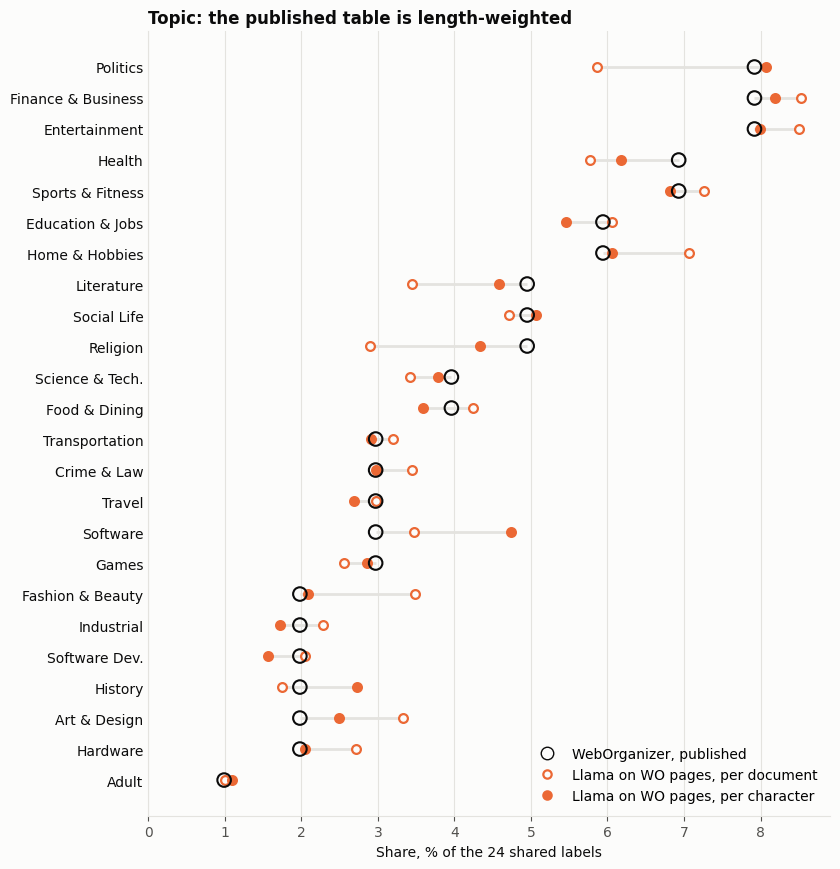

,published,llama_wo_doc,llama_wo_char
Entertainment,7.9,8.5,8.0
Finance & Business,7.9,8.5,8.2
Politics,7.9,5.9,8.1
Sports & Fitness,6.9,7.3,6.8
Health,6.9,5.8,6.2
Home & Hobbies,5.9,7.1,6.1
Education & Jobs,5.9,6.1,5.5
Religion,5.0,2.9,4.3
Social Life,5.0,4.7,5.1
Literature,5.0,3.4,4.6


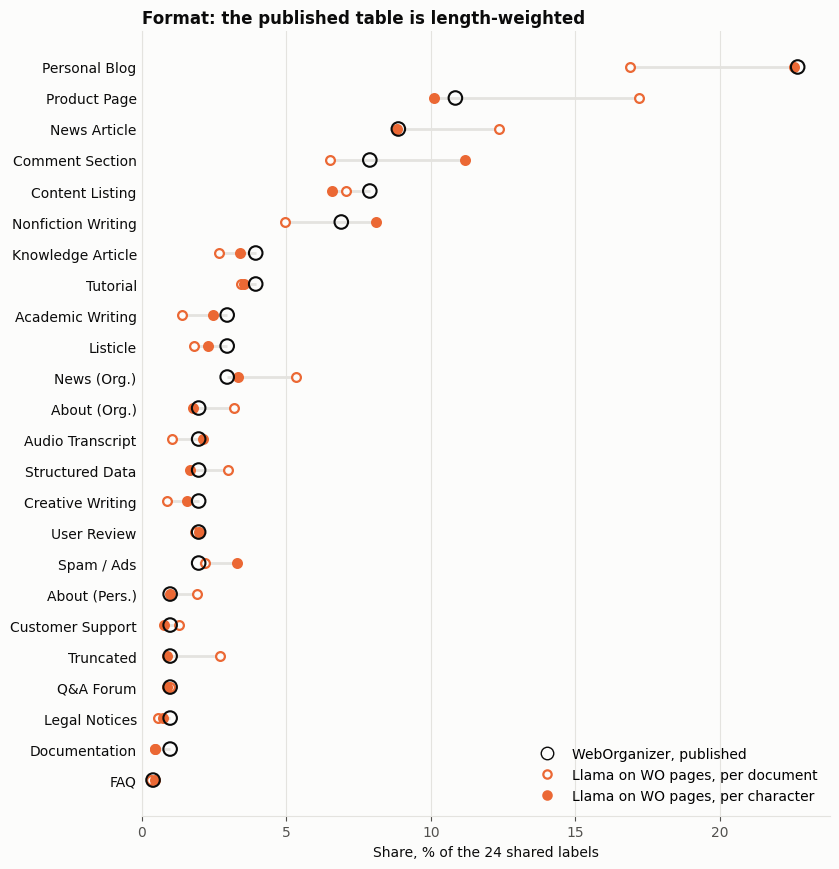

,published,llama_wo_doc,llama_wo_char
Personal Blog,22.7,16.9,22.5
Product Page,10.8,17.2,10.1
News Article,8.9,12.4,8.8
Content Listing,7.9,7.1,6.6
Comment Section,7.9,6.5,11.2
Nonfiction Writing,6.9,5.0,8.1
Tutorial,3.9,3.4,3.6
Knowledge Article,3.9,2.7,3.4
Academic Writing,3.0,1.4,2.5
News (Org.),3.0,5.3,3.3


In [8]:
def plot_labels(label_type: str, series: list[tuple[str, str, str, bool]], title: str, note: str = "") -> None:
    """A dot per distribution and label; labels sorted by the published share.

    Args:
        label_type: "topic" or "format".
        series: (column, legend name, colour, filled) per distribution, drawn after the published ring.
        title: Chart title.
        note: Text after the x-axis label.
    """
    table = shares[label_type]
    order = table["published"].sort_values().index
    fig, ax = plt.subplots(figsize=(8.5, 0.3 * len(order) + 1.6))
    y = np.arange(len(order))
    columns = ["published", *[column for column, *_ in series]]
    ax.hlines(y, table.loc[order, columns].min(axis=1), table.loc[order, columns].max(axis=1), color=GRID,
              linewidth=2, zorder=1)
    handles = []
    for column, name, color, filled in series:
        ax.scatter(table.loc[order, column], y, s=40, color=color if filled else SURFACE, edgecolor=color,
                   linewidth=1.6, zorder=3)
        handles.append(Line2D([], [], marker="o", linestyle="", markerfacecolor=color if filled else SURFACE,
                              markeredgecolor=color, markeredgewidth=1.6, label=name))
    ax.scatter(table.loc[order, "published"], y, s=95, facecolor="none", edgecolor=TEXT, linewidth=1.5, zorder=4)
    handles.insert(0, Line2D([], [], marker="o", linestyle="", markerfacecolor="none", markeredgecolor=TEXT,
                             markersize=9, label="WebOrganizer, published"))
    ax.set_yticks(y, order)
    ax.tick_params(axis="y", colors=TEXT, length=0)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(left=0)
    ax.set_xlabel("Share, % of the 24 shared labels" + note)
    ax.set_title(title, loc="left")
    ax.legend(handles=handles, loc="lower right")
    plt.tight_layout()
    plt.show()


weighting_rows = []
for label_type in LABEL_TYPES:
    distance = distance_to(label_type, "published")
    weighting_rows.append({"label_type": label_type, "Llama, per document": distance["llama_wo_doc"],
                           "Llama, per character": distance["llama_wo_char"], "rounding alone": rounding[label_type]})
display(Markdown("JSD from the published table, bits:"))
display(pd.DataFrame(weighting_rows).set_index("label_type").round(3))

for label_type in LABEL_TYPES:
    plot_labels(label_type, [("llama_wo_doc", "Llama on WO pages, per document", COLORS["llama_wo"], False),
                             ("llama_wo_char", "Llama on WO pages, per character", COLORS["llama_wo"], True)],
                f"{label_type.capitalize()}: the published table is length-weighted")
    display(shares[label_type][["published", "llama_wo_doc", "llama_wo_char"]].round(1))

## 3. Our English against the published table

Our English pages labelled by Qwen, for each collection and both weightings, against the
published table. **Per character** is the like-for-like comparison with the table (section
2); per document is shown because our other notebooks count documents.

The chart shows the main collection per character (blue) against the published table, and
the bar chart after it the difference per label in percentage points (red: more in ours,
blue: less).

In [9]:
comparison_rows = []
for label_type in LABEL_TYPES:
    distance = distance_to(label_type, "published")
    for collection in [*HPLT_COLLECTIONS, "hplt_all"]:
        comparison_rows.append({"label_type": label_type, "HPLT English": collection,
                                "per document": distance[f"{collection}_doc"],
                                "per character": distance[f"{collection}_char"]})
comparison = pd.DataFrame(comparison_rows).pivot(index="HPLT English", columns="label_type",
                                                  values=["per character", "per document"])
display(Markdown("JSD from the published table, bits (rounding alone: "
                 + ", ".join(f"{t} {v:.3f}" for t, v in rounding.items()) + "; for scale, English vs. "
                 + ", ".join(f"{language} {scale.loc[language, 'topic']:.3f} topic / {scale.loc[language, 'format']:.3f} format"
                             for language in SCALE_LANGUAGES) + "):"))
display(comparison.loc[[*HPLT_COLLECTIONS, "hplt_all"]].round(3))

JSD from the published table, bits (rounding alone: topic 0.001, format 0.002; for scale, English vs. german 0.009 topic / 0.022 format, finnish 0.018 topic / 0.033 format):

per character        per document       
label_type          format  topic       format  topic
HPLT English                                         
clean_random         0.082  0.020        0.084  0.021
noisy_random         0.186  0.082        0.227  0.074
poor_random          0.270  0.075        0.307  0.094
hplt_all             0.107  0.027        0.145  0.046

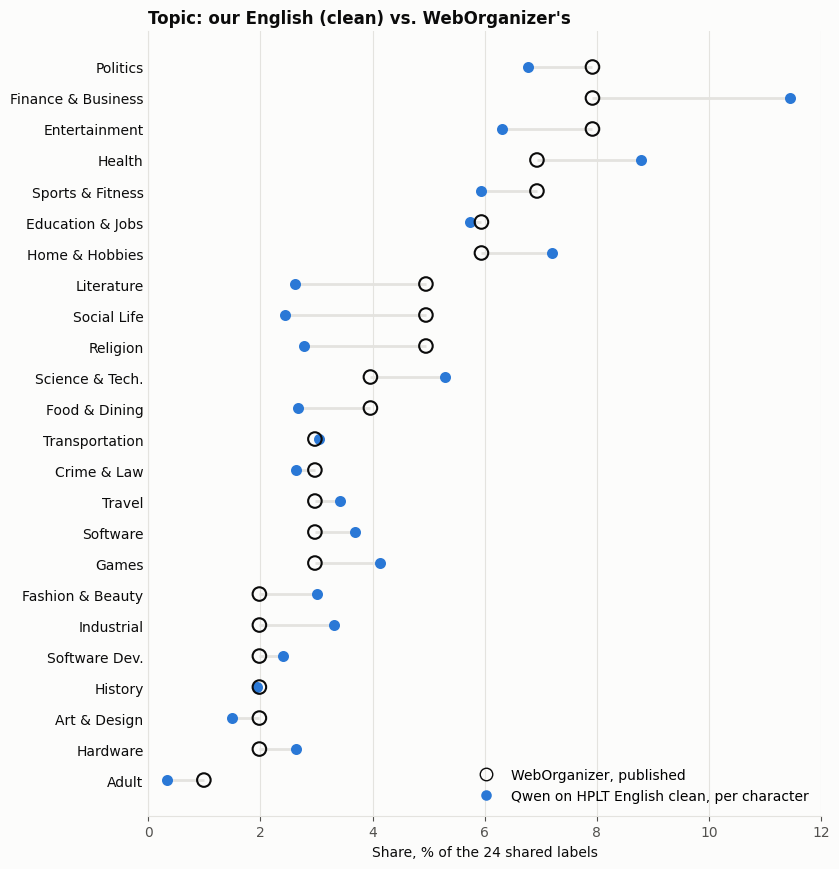

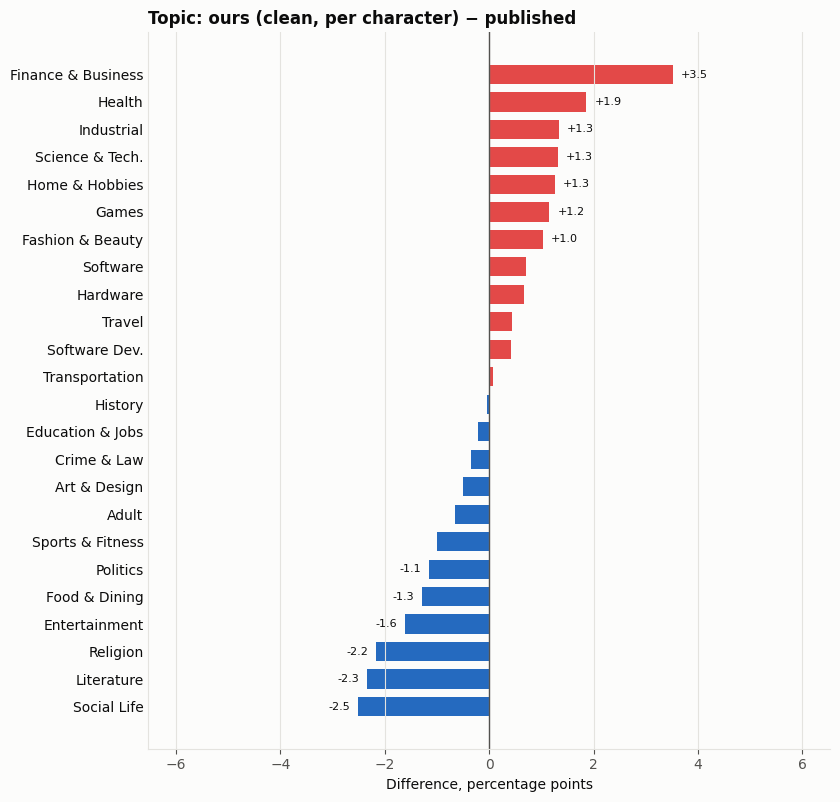

,published,clean_random_char,clean_random_doc,hplt_all_char,difference (char)
Entertainment,7.9,6.3,7.4,6.8,-1.6
Finance & Business,7.9,11.4,10.0,8.4,3.5
Politics,7.9,6.8,6.4,6.3,-1.1
Sports & Fitness,6.9,5.9,6.6,5.0,-1.0
Health,6.9,8.8,6.5,6.8,1.9
Home & Hobbies,5.9,7.2,8.9,6.5,1.3
Education & Jobs,5.9,5.7,6.3,5.4,-0.2
Religion,5.0,2.8,2.4,3.2,-2.2
Social Life,5.0,2.4,2.4,2.6,-2.5
Literature,5.0,2.6,2.3,3.2,-2.3


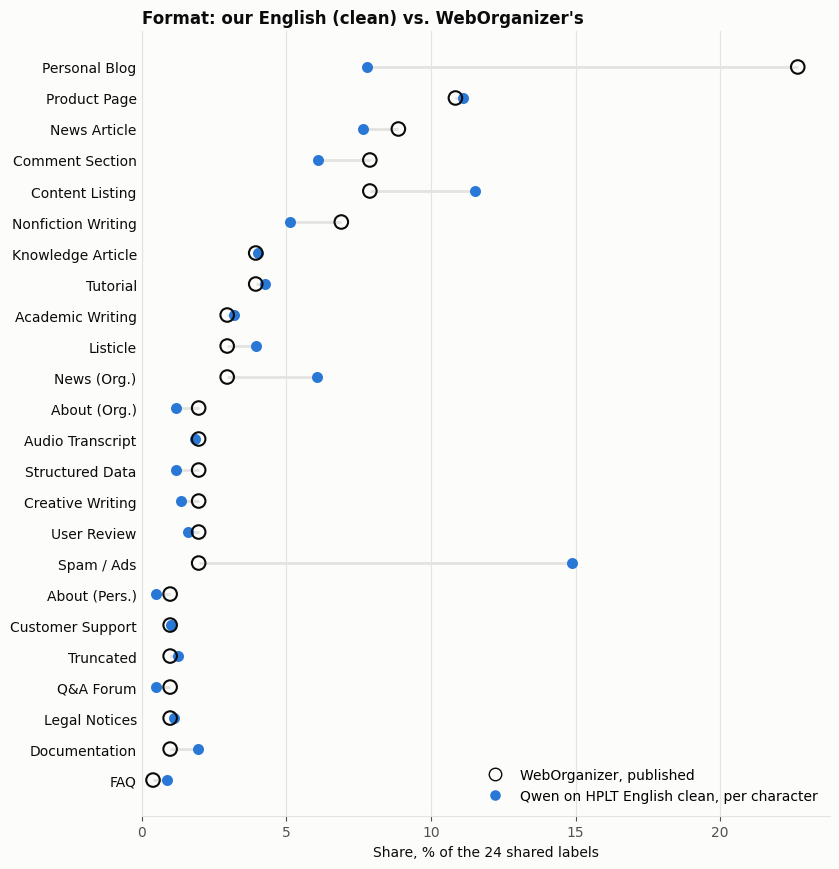

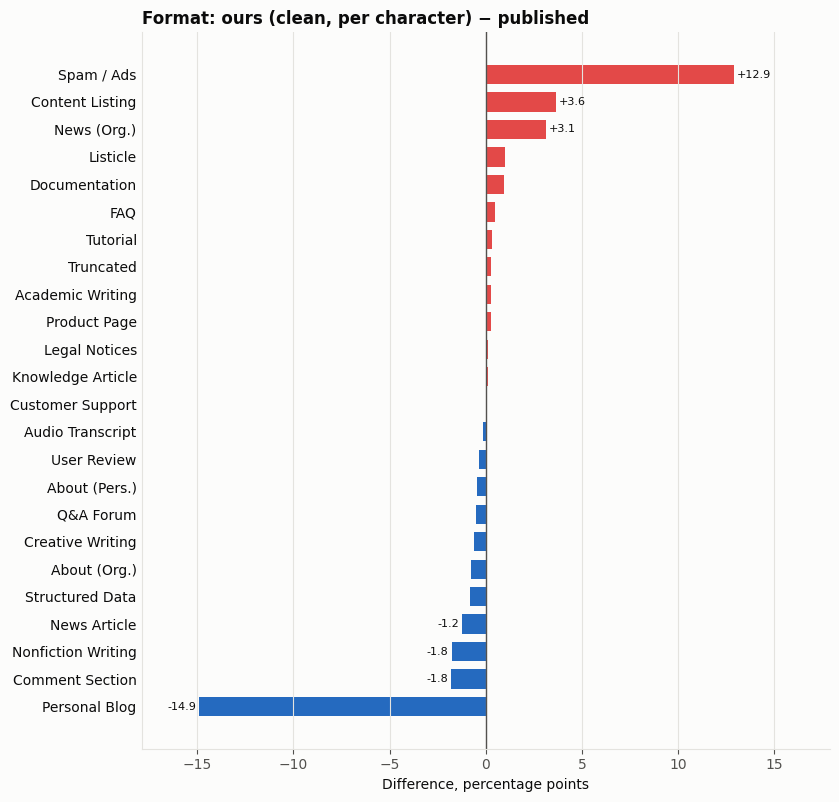

,published,clean_random_char,clean_random_doc,hplt_all_char,difference (char)
Personal Blog,22.7,7.8,7.5,7.0,-14.9
Product Page,10.8,11.1,19.6,10.0,0.2
News Article,8.9,7.6,11.7,5.0,-1.2
Content Listing,7.9,11.5,11.4,16.2,3.6
Comment Section,7.9,6.1,4.5,7.4,-1.8
Nonfiction Writing,6.9,5.1,3.6,3.9,-1.8
Tutorial,3.9,4.2,3.4,2.9,0.3
Knowledge Article,3.9,4.0,3.1,3.4,0.1
Academic Writing,3.0,3.2,1.9,2.6,0.2
News (Org.),3.0,6.1,7.3,4.3,3.1


In [10]:
def plot_difference(label_type: str, column: str, reference: str, title: str) -> None:
    """Horizontal bars of shares[column] − shares[reference], in percentage points."""
    difference = (shares[label_type][column] - shares[label_type][reference]).sort_values()
    fig, ax = plt.subplots(figsize=(8.5, 0.28 * len(difference) + 1.4))
    y = np.arange(len(difference))
    ax.barh(y, difference, height=0.7, color=[UP if value > 0 else DOWN for value in difference])
    for position, value in zip(y, difference):
        if abs(value) >= 1:
            ax.text(value + (0.15 if value > 0 else -0.15), position, f"{value:+.1f}", va="center",
                    ha="left" if value > 0 else "right", fontsize=8, color=TEXT)
    ax.axvline(0, color=MUTED, linewidth=1)
    ax.set_yticks(y, difference.index)
    ax.tick_params(axis="y", colors=TEXT, length=0)
    ax.grid(axis="y", visible=False)
    limit = difference.abs().max() + 3
    ax.set_xlim(-limit, limit)
    ax.set_xlabel("Difference, percentage points")
    ax.set_title(title, loc="left")
    plt.tight_layout()
    plt.show()


main = MAIN_COLLECTION.removesuffix("_random")
for label_type in LABEL_TYPES:
    plot_labels(label_type, [(f"{MAIN_COLLECTION}_char", f"Qwen on HPLT English {main}, per character",
                              COLORS["qwen_hplt"], True)],
                f"{label_type.capitalize()}: our English ({main}) vs. WebOrganizer's")
    plot_difference(label_type, f"{MAIN_COLLECTION}_char", "published",
                    f"{label_type.capitalize()}: ours ({main}, per character) − published")
    columns = ["published", f"{MAIN_COLLECTION}_char", f"{MAIN_COLLECTION}_doc", "hplt_all_char"]
    display(shares[label_type][columns].assign(**{"difference (char)": shares[label_type][f"{MAIN_COLLECTION}_char"]
                                                  - shares[label_type]["published"]}).round(1))

## 4. Labeller or pages?

Two things differ between the published table and our English: the labeller (Llama with
WebOrganizer's prompt vs. Qwen with ours) and the pages (WebOrganizer's corpus vs. HPLT).
Qwen's labels on WebOrganizer's own pages separate them:

1. **Labeller effect:** Llama → Qwen on the same WebOrganizer pages.
2. **Page effect:** Qwen on WebOrganizer's pages → Qwen on our English pages
   (`MAIN_COLLECTION`).

Both steps are measured with the same weighting at both ends, per document and per
character. JSD doesn't add up exactly along a path, but the two steps show which effect is
larger. The last column is the whole distance, Llama on WebOrganizer's pages to Qwen on
ours.

In [11]:
steps = []
for label_type in LABEL_TYPES:
    table = shares[label_type]
    for weighting in ("doc", "char"):
        llama, qwen, ours = (table[f"llama_wo_{weighting}"], table[f"qwen_wo_{weighting}"],
                             table[f"{MAIN_COLLECTION}_{weighting}"])
        steps.append({"label_type": label_type, "weighting": "per document" if weighting == "doc" else "per character",
                      "labeller (Llama → Qwen, WO pages)": js_bits(llama, qwen),
                      f"pages (WO → HPLT {main}, Qwen)": js_bits(qwen, ours),
                      "whole (Llama on WO → Qwen on HPLT)": js_bits(llama, ours)})
display(pd.DataFrame(steps).set_index(["label_type", "weighting"]).round(3))

labeller (Llama → Qwen, WO pages)  pages (WO → HPLT clean, Qwen)  whole (Llama on WO → Qwen on HPLT)
label_type weighting                                                                                                          
topic      per document                               0.003                          0.007                               0.010
           per character                              0.003                          0.023                               0.021
format     per document                               0.010                          0.028                               0.045
           per character                              0.014                          0.052                               0.081

### Chart: the two steps per label

Three dots per label: Llama on WebOrganizer's pages (orange), Qwen on the same pages
(aqua) and Qwen on our English pages (blue), joined by a grey line; first per document,
then per character. Orange to
aqua is the labeller effect, aqua to blue the page effect. Only labels where some step is
at least 1 point are shown, sorted by Llama's share. The table lists every label with both
steps.

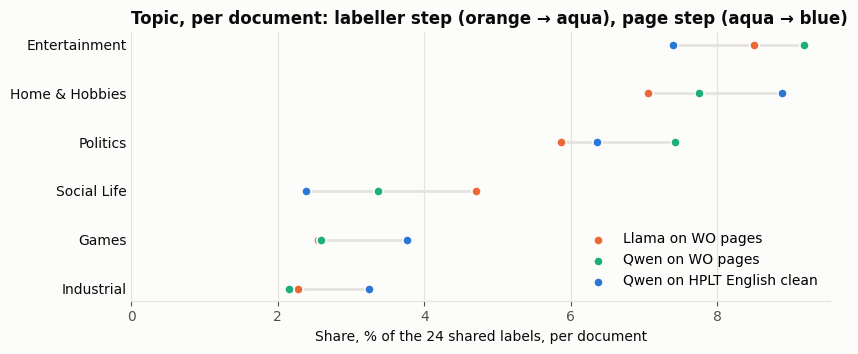

,llama_wo_doc,qwen_wo_doc,clean_random_doc,labeller step,page step
Finance & Business,8.5,9.1,10.0,0.6,0.9
Entertainment,8.5,9.2,7.4,0.7,-1.8
Sports & Fitness,7.3,7.4,6.6,0.1,-0.8
Home & Hobbies,7.1,7.8,8.9,0.7,1.1
Education & Jobs,6.1,5.4,6.3,-0.6,0.9
Politics,5.9,7.4,6.4,1.6,-1.1
Health,5.8,5.6,6.5,-0.1,0.9
Social Life,4.7,3.4,2.4,-1.3,-1.0
Food & Dining,4.2,4.0,3.3,-0.3,-0.7
Fashion & Beauty,3.5,3.6,4.5,0.1,0.9


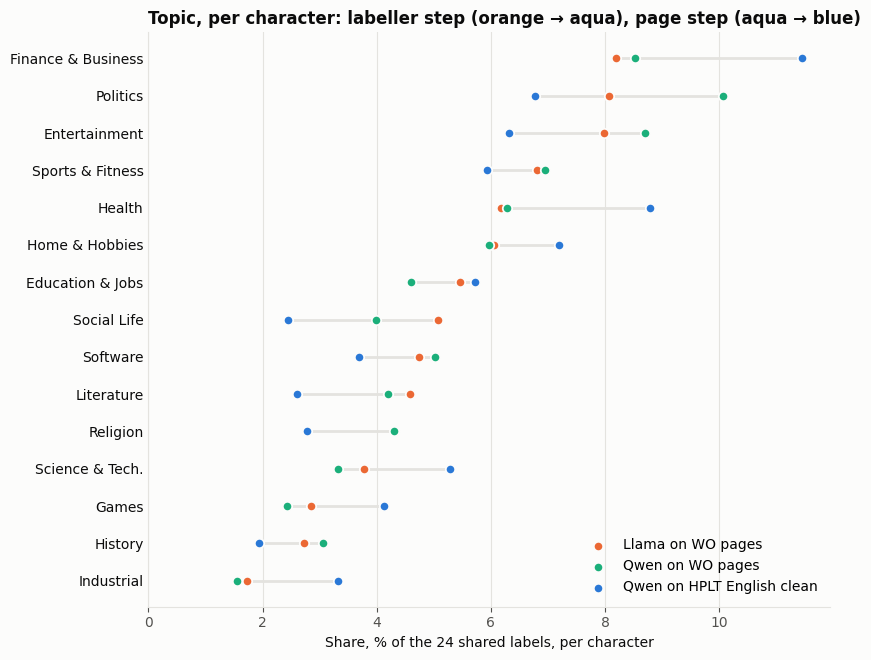

,llama_wo_char,qwen_wo_char,clean_random_char,labeller step,page step
Finance & Business,8.2,8.5,11.4,0.3,2.9
Politics,8.1,10.1,6.8,2.0,-3.3
Entertainment,8.0,8.7,6.3,0.7,-2.4
Sports & Fitness,6.8,7.0,5.9,0.1,-1.0
Health,6.2,6.3,8.8,0.1,2.5
Home & Hobbies,6.1,6.0,7.2,-0.1,1.2
Education & Jobs,5.5,4.6,5.7,-0.9,1.1
Social Life,5.1,4.0,2.4,-1.1,-1.6
Software,4.7,5.0,3.7,0.3,-1.3
Literature,4.6,4.2,2.6,-0.4,-1.6


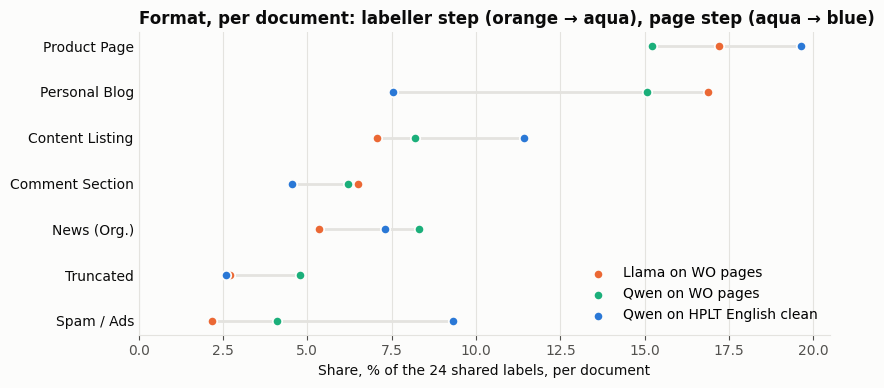

,llama_wo_doc,qwen_wo_doc,clean_random_doc,labeller step,page step
Product Page,17.2,15.2,19.6,-2.0,4.4
Personal Blog,16.9,15.1,7.5,-1.8,-7.5
News Article,12.4,12.5,11.7,0.2,-0.9
Content Listing,7.1,8.2,11.4,1.1,3.2
Comment Section,6.5,6.2,4.5,-0.3,-1.7
News (Org.),5.3,8.3,7.3,3.0,-1.0
Nonfiction Writing,5.0,4.2,3.6,-0.7,-0.6
Tutorial,3.4,2.8,3.4,-0.6,0.5
About (Org.),3.2,2.9,2.2,-0.3,-0.7
Structured Data,3.0,2.0,1.1,-0.9,-0.9


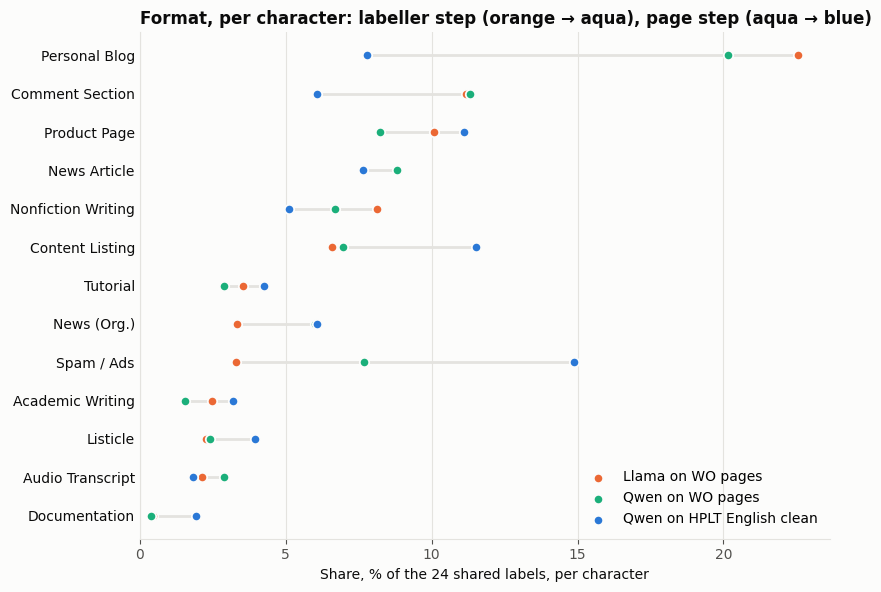

,llama_wo_char,qwen_wo_char,clean_random_char,labeller step,page step
Personal Blog,22.5,20.1,7.8,-2.4,-12.3
Comment Section,11.2,11.3,6.1,0.1,-5.2
Product Page,10.1,8.2,11.1,-1.9,2.9
News Article,8.8,8.8,7.6,0.0,-1.2
Nonfiction Writing,8.1,6.7,5.1,-1.4,-1.6
Content Listing,6.6,7.0,11.5,0.4,4.6
Tutorial,3.6,2.9,4.2,-0.7,1.4
Knowledge Article,3.4,3.1,4.0,-0.4,1.0
News (Org.),3.3,6.0,6.1,2.6,0.1
Spam / Ads,3.3,7.7,14.9,4.4,7.2


In [12]:
def plot_steps(label_type: str, weighting: str = "doc", minimum: float = 1.0) -> pd.DataFrame:
    table = shares[label_type]
    columns = [f"llama_wo_{weighting}", f"qwen_wo_{weighting}", f"{MAIN_COLLECTION}_{weighting}"]
    data = table[columns].copy()
    data["labeller step"] = data[columns[1]] - data[columns[0]]
    data["page step"] = data[columns[2]] - data[columns[1]]
    shown = data[(data[["labeller step", "page step"]].abs() >= minimum).any(axis=1)].sort_values(columns[0])
    fig, ax = plt.subplots(figsize=(8.5, 0.34 * len(shown) + 1.6))
    y = np.arange(len(shown))
    ax.hlines(y, shown[columns].min(axis=1), shown[columns].max(axis=1), color=GRID, linewidth=2, zorder=1)
    names = ["Llama on WO pages", "Qwen on WO pages", f"Qwen on HPLT English {main}"]
    for column, name, key in zip(columns, names, ("llama_wo", "qwen_wo", "qwen_hplt")):
        ax.scatter(shown[column], y, s=46, color=COLORS[key], edgecolor=SURFACE, linewidth=1.3, zorder=3, label=name)
    ax.set_yticks(y, shown.index)
    ax.tick_params(axis="y", colors=TEXT, length=0)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(left=0)
    per = "per document" if weighting == "doc" else "per character"
    ax.set_xlabel(f"Share, % of the 24 shared labels, {per}")
    ax.set_title(f"{label_type.capitalize()}, {per}: labeller step (orange → aqua), page step (aqua → blue)",
                 loc="left")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()
    return data


for label_type in LABEL_TYPES:
    for weighting in ("doc", "char"):
        data = plot_steps(label_type, weighting)
        display(data.sort_values(f"llama_wo_{weighting}", ascending=False).round(1))

## 5. What renormalising leaves out

Our labels give Other and Bad example probability that the comparison above drops. The
table shows how much, per document, on WebOrganizer's pages and on each HPLT collection.
A large share would make the renormalised comparison less meaningful.

In [13]:
dropped_rows = []
for label_type in LABEL_TYPES:
    qwen = wo_pages[label_type]["qwen"]
    row = {"label_type": label_type, "WO pages": 100 * qwen[SPECIAL].sum().sum() / len(qwen)}
    for collection in HPLT_COLLECTIONS:
        result = hplt[collection, label_type]
        row[f"HPLT {collection.removesuffix('_random')}"] = 100 * result["per_doc"][SPECIAL].sum() / result["n"]
    dropped_rows.append(row)
display(Markdown("Other + Bad example, % of the probability (per document):"))
display(pd.DataFrame(dropped_rows).set_index("label_type").round(2))

Other + Bad example, % of the probability (per document):

,WO pages,HPLT clean,HPLT noisy,HPLT poor
label_type,,,,
topic,1.90,2.28,3.29,8.61
format,0.97,0.95,5.60,15.69


## 6. Findings (25 November 2026)

What the notebook showed when it was written. All shares are over the 24 shared labels;
distances are JSD in bits.

**The published table is length-weighted, not per document.** Llama's labels on WebOrganizer's
10,000 validation pages, weighted by characters, reproduce it to within 0.003 bits (topic) and
0.006 (format). Per document they are three to five times further away (0.009 and 0.029); rounding
to whole percents alone accounts for 0.001–0.002. For example:

| Format label | Published | Llama, per character | Llama, per document |
|---|---|---|---|
| Personal Blog | 22.7% | 22.5% | 16.9% |
| Product Page | 10.8% | 10.1% | 17.2% |

So the table describes WebOrganizer's corpus by volume of text (most likely tokens; characters
stand in for them here), while our other notebooks count documents. Compare like with like.

**Topic: similar.** Our clean English is 0.020 bits from the published table, per character.
That is about the distance between English and Finnish in our own clean data (0.018), and twice
English–German (0.009). Per character, ours has more Finance & Business (+3.5 points) and Health
(+1.9), and less Social Life (−2.5), Literature (−2.3), Religion (−2.2) and Entertainment (−1.6).

**Format: clearly different.** Ours is 0.082 bits from the table, per character, two and a half
times the English–Finnish distance. The difference sits in a few labels:

- *Two labels carry most of it:* Personal Blog is 7.8% against 22.7% (−14.9 points), and Spam /
  Ads 14.9% against 2.0% (+12.9).
- *Smaller differences:* Content Listing +3.6, News (Org.) +3.1.
- *Product Page* looks doubled when counted per document (19.6% vs. 10.8%), but matches once
  weighted by length (11.1%).

**Mostly the pages, partly the labeller.** On the same WebOrganizer pages, Qwen and Llama are
close: topic 0.003 bits; format 0.010 per document, 0.014 per character. Moving Qwen from
WebOrganizer's pages to our clean English pages is two to four times larger: topic 0.007 / 0.023,
format 0.028 / 0.052 (per document / per character). Per character, step by step (Llama on WO
pages → Qwen on WO pages → Qwen on HPLT clean):

| Format label | Llama, WO | Qwen, WO | Qwen, HPLT clean | Labeller step | Page step |
|---|---|---|---|---|---|
| Personal Blog | 22.5% | 20.1% | 7.8% | −2.4 | −12.3 |
| Comment Section | 11.2% | 11.3% | 6.1% | +0.1 | −5.2 |
| Spam / Ads | 3.3% | 7.7% | 14.9% | +4.4 | +7.2 |
| News (Org.) | 3.3% | 6.0% | 6.1% | +2.6 | +0.1 |

So our clean English has far fewer long blogs and comment threads and much more long spam than
WebOrganizer's corpus. On top of that, Qwen calls pages spam more readily than Llama does, and
uses News (Org.) more (as in `weborganizer_comparison.ipynb`).

**The other HPLT collections are further away.** In format, per character, noisy English is 0.19
bits from the table and poor 0.27; all three pooled 0.107. Clean is the closest, as expected for
a comparison with a filtered corpus. Renormalising drops little from clean: Other and Bad example
hold 2.3% (topic) and 1.0% (format) of the probability, close to the 1.9% and 1.0% on
WebOrganizer's pages. Poor loses 8.6% and 15.7%, so its comparison leaves out more.

**Implications.**

- When putting our label proportions next to WebOrganizer's, weight ours by length, or compare
  per document against Llama on WebOrganizer's validation pages.
- The format difference is mostly real: our English training data has fewer blogs and more spam
  than WebOrganizer's. It isn't mainly a labeller artefact, though the labeller accounts for about
  40% of the Spam / Ads difference (4.4 of 11.6 points, per character).